In [1]:
import numpy as np
from statsmodels.tsa.arima.model import ARIMA
import matplotlib.pyplot as plt
import pandas as pd
from datetime import datetime, timedelta
from time import time

In [2]:
URL = "https://raw.githubusercontent.com/selva86/datasets/master/a10.csv"

In [3]:
df = pd.read_csv(URL)

In [4]:
df['date'] = pd.to_datetime(df['date'])
df = df.set_index('date') # Chuyển sang lấy cột Date làm cột chính
df = df.asfreq('MS') 
df['value'] = df['value'].interpolate()

In [5]:
df

,value
date,
1991-07-01,3.526591
1991-08-01,3.180891
1991-09-01,3.252221
1991-10-01,3.611003
1991-11-01,3.565869
...,...
2008-02-01,21.654285
2008-03-01,18.264945
2008-04-01,23.107677


## Split data

In [6]:
train_end = datetime(2004, 12, 1) #2004-12-01
test_end = datetime(2008, 6, 1) #2008-06-01

train_data = df[:train_end]
test_data = df[train_end + timedelta(days=1) : test_end]

## Train

In [7]:
model_1 = ARIMA(train_data, order=(1, 1, 1))

In [8]:
model_2 = ARIMA(train_data, order=(2, 1, 1))

## Fit it

In [9]:
model_1_fit =  model_1.fit()

In [10]:
model_2_fit =  model_2.fit()

In [11]:
model_1_fit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                  value   No. Observations:                  162
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -283.830
Date:                Sun, 25 Oct 2026   AIC                            573.659
Time:                        08:58:48   BIC                            582.904
Sample:                    07-01-1991   HQIC                           577.413
                         - 12-01-2004                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3157      0.208      1.514      0.130      -0.093       0.724
ma.L1         -0.8220      0.113     -7.257      0.000      -1.044      -0.600
sigma2         1.9819      0.182     10.879      0.000       1.625       2.339
===================================================================================
Ljung-Box (L1) (Q):                   0.41   Jarque-Bera (JB):               103.35
Prob(Q):                              0.52   Prob(JB):                         0.00
Heteroskedasticity (H):               5.15   Skew:                            -0.95
Prob(H) (two-sided):                  0.00   Kurtosis:                         6.43
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [12]:
AIC1 = model_1_fit.aic
BIC1 = model_1_fit.bic
print(f"AIC of model 1 is :{AIC1} \nBIC of model 1 is: {BIC1}")

AIC of model 1 is :573.6593246169494 
BIC of model 1 is: 582.9035377119028


In [13]:
model_2_fit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                  value   No. Observations:                  162
Model:                 ARIMA(2, 1, 1)   Log Likelihood                -283.829
Date:                Sun, 25 Oct 2026   AIC                            575.657
Time:                        08:58:48   BIC                            587.983
Sample:                    07-01-1991   HQIC                           580.662
                         - 12-01-2004                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3158      0.235      1.341      0.180      -0.146       0.777
ar.L2         -0.0039      0.139     -0.028      0.978      -0.277       0.269
ma.L1         -0.8211      0.157     -5.219      0.000      -1.129      -0.513
sigma2         1.9818      0.182     10.877      0.000       1.625       2.339
===================================================================================
Ljung-Box (L1) (Q):                   0.43   Jarque-Bera (JB):               102.86
Prob(Q):                              0.51   Prob(JB):                         0.00
Heteroskedasticity (H):               5.16   Skew:                            -0.95
Prob(H) (two-sided):                  0.00   Kurtosis:                         6.43
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [14]:
AIC2 = model_2_fit.aic
BIC2 = model_2_fit.bic
print(f"AIC of model 2 is :{AIC2} \nBIC of model 2 is: {BIC2}")

AIC of model 2 is :575.657297885912 
BIC of model 2 is: 587.9829153458498


In [15]:
# AIC càng thấp càng tốt -> dùng model có AIC nhỏ hơn cho phần 3, 4
best_fit  = model_1_fit if AIC1 < AIC2 else model_2_fit
best_name = "ARIMA(1,1,1)" if AIC1 < AIC2 else "ARIMA(2,1,1)"
print("Chọn:", best_name)

Chọn: ARIMA(1,1,1)


## Phần 3: Chẩn đoán phần dư (residuals)

Residual = y thực tế − y dự báo. Mô hình tốt thì residual giống nhiễu trắng: mean ≈ 0 và không tự tương quan. Kiểm định Ljung-Box: H0 = không có tự tương quan, p < 0.05 → bác bỏ (residual còn quy luật).

Mean residual: 0.3266


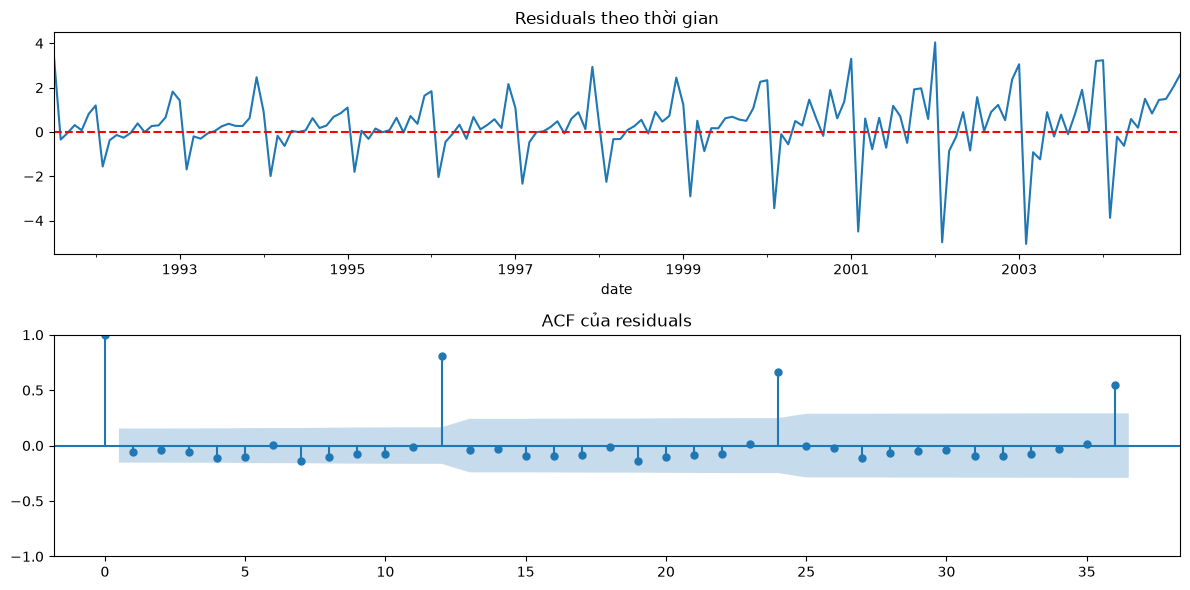

,lb_stat,lb_pvalue
12,128.849164,1.050337e-21
24,226.738159,6.406180e-35


In [16]:
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf

resid = best_fit.resid.dropna()
print(f"Mean residual: {resid.mean():.4f}")

fig, axes = plt.subplots(2, 1, figsize=(12, 6))
resid.plot(ax=axes[0], title="Residuals theo thời gian")
axes[0].axhline(0, color="red", linestyle="--")
plot_acf(resid, lags=36, ax=axes[1], title="ACF của residuals")
plt.tight_layout(); plt.show()

acorr_ljungbox(resid, lags=[12, 24], return_df=True)

Mean residual ≈ 0.33 nhưng ACF còn đỉnh rất lớn ở lag 12 (≈ 0.81) và 24, Ljung-Box p ≈ 0 → residual **chưa phải nhiễu trắng**: ARIMA không bắt được mùa vụ 12 tháng (tháng 1 cao, tháng 2 thấp). Hướng khắc phục: SARIMA.

## Phần 4: Dự đoán trên tập test

Dự báo 42 tháng của test kèm khoảng tin cậy 95%, rồi tính sai số MAE / RMSE / MAPE.

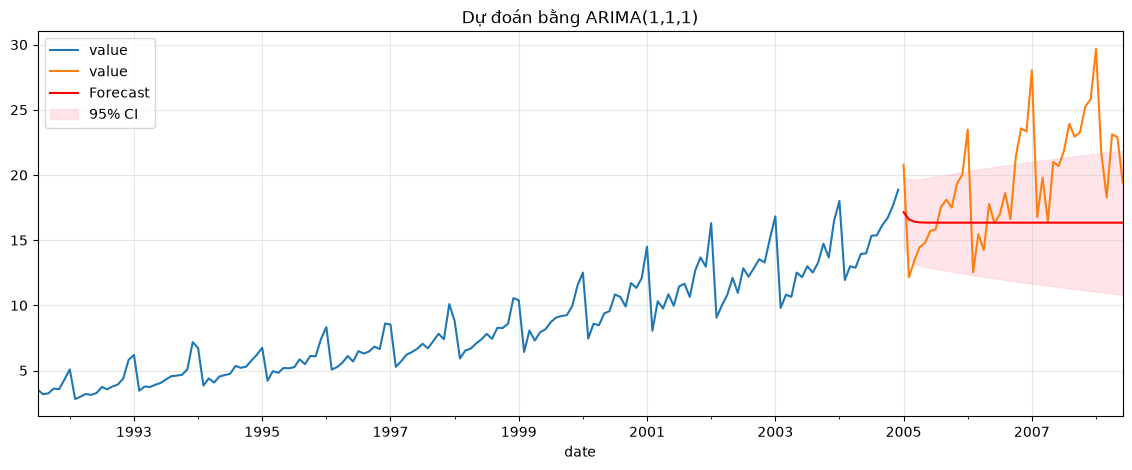

In [17]:
fc   = best_fit.get_forecast(steps=len(test_data))
pred = pd.Series(fc.predicted_mean.to_numpy(), index=test_data.index)
ci   = fc.conf_int()

fig, ax = plt.subplots(figsize=(14, 5))
train_data.plot(ax=ax, label="Train")
test_data.plot(ax=ax, label="Test")
pred.plot(ax=ax, label="Forecast", color="red")
ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color="pink", alpha=0.4, label="95% CI")
ax.set_title(f"Dự đoán bằng {best_name}")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

In [18]:
err  = test_data["value"] - pred
mae  = err.abs().mean()
rmse = np.sqrt((err ** 2).mean())
mape = (err.abs() / test_data["value"]).mean() * 100

print(f"MAE  = {mae:.2f}")
print(f"RMSE = {rmse:.2f}")
print(f"MAPE = {mape:.2f}%")
print("Sai lệch lớn nhất:", err.abs().idxmax().date(), "=", round(err.abs().max(), 2))

MAE  = 4.07
RMSE = 5.18
MAPE = 19.12%
Sai lệch lớn nhất: 2008-01-01 = 13.32


Dự báo gần như phẳng vì ARIMA không có thành phần mùa vụ; sai lệch lớn nhất ở 01/2008 (tháng cao điểm) — khớp kết luận Phần 3.

Biến `pred`, `ci`, `err`, MAE/RMSE/MAPE bàn giao cho Phần 5 lập bảng đánh giá.

## Mở rộng: SARIMA

Phần 3 cho thấy residual của ARIMA còn nguyên mùa vụ 12 tháng. SARIMA(p,d,q)(P,D,Q)₁₂ thêm thành phần mùa vụ vào ARIMA để sửa đúng chỗ đó. Chạy 2 ứng viên — `SARIMA(1,1,1)(1,1,1)₁₂` và `SARIMA(0,1,1)(0,1,1)₁₂` (gợi ý của Bài 4) — rồi chọn theo AIC, giống logic Phần 2. Sau đó làm lại đúng Phần 3 (chẩn đoán phần dư) và Phần 4 (dự đoán) để so sánh.

In [19]:
# SARIMA = ARIMA + thanh phan mua vu (P,D,Q) chu ky 12 thang
sarima_1 = ARIMA(train_data, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12))
sarima_2 = ARIMA(train_data, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12))

sarima_1_fit = sarima_1.fit()
sarima_2_fit = sarima_2.fit()

AIC1_s, BIC1_s = sarima_1_fit.aic, sarima_1_fit.bic
AIC2_s, BIC2_s = sarima_2_fit.aic, sarima_2_fit.bic
print(f"AIC/BIC of SARIMA(1,1,1)(1,1,1)12 is :{AIC1_s:.2f} / {BIC1_s:.2f}")
print(f"AIC/BIC of SARIMA(0,1,1)(0,1,1)12 is :{AIC2_s:.2f} / {BIC2_s:.2f}")

sarima_fit  = sarima_1_fit if AIC1_s < AIC2_s else sarima_2_fit
sarima_name = "SARIMA(1,1,1)(1,1,1)12" if AIC1_s < AIC2_s else "SARIMA(0,1,1)(0,1,1)12"
print("Chọn:", sarima_name)

AIC/BIC of SARIMA(1,1,1)(1,1,1)12 is :244.79 / 259.81
AIC/BIC of SARIMA(0,1,1)(0,1,1)12 is :248.88 / 257.89
Chọn: SARIMA(1,1,1)(1,1,1)12


## Phần 3 (SARIMA): Chẩn đoán phần dư

Lặp lại đúng các kiểm tra của Phần 3 trên residual của SARIMA.

Mean residual: 0.0703


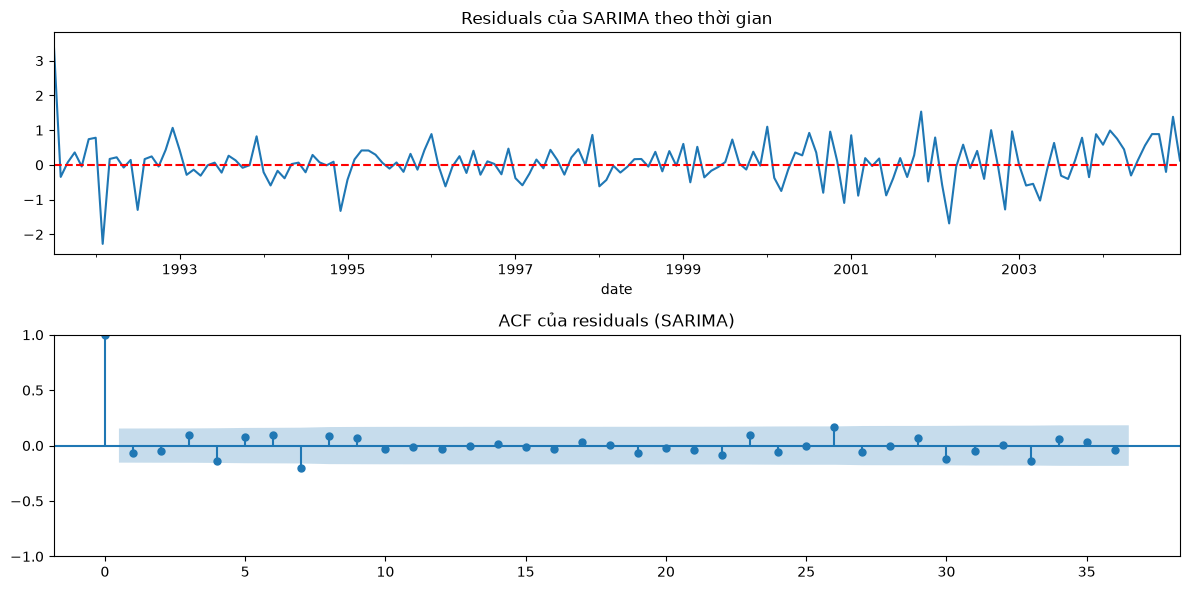

,lb_stat,lb_pvalue
12,17.796648,0.122006
24,23.026543,0.518232


In [20]:
resid_s = sarima_fit.resid.dropna()
print(f"Mean residual: {resid_s.mean():.4f}")

fig, axes = plt.subplots(2, 1, figsize=(12, 6))
resid_s.plot(ax=axes[0], title="Residuals của SARIMA theo thời gian")
axes[0].axhline(0, color="red", linestyle="--")
plot_acf(resid_s, lags=36, ax=axes[1], title="ACF của residuals (SARIMA)")
plt.tight_layout(); plt.show()

acorr_ljungbox(resid_s, lags=[12, 24], return_df=True)

Khác hẳn ARIMA: mean residual ≈ 0.07, ACF **không còn đỉnh** ở lag 12/24, Ljung-Box p = 0.12 (lag 12) và 0.52 (lag 24) → **không bác bỏ H0**: residual của SARIMA đã giống nhiễu trắng. Thành phần (P,D,Q)₁₂ đã hấp thụ phần mùa vụ mà ARIMA bỏ sót.

## Phần 4 (SARIMA): Dự đoán trên tập test

Dự báo lại 42 tháng bằng SARIMA, cùng cách tính sai số như Phần 4.

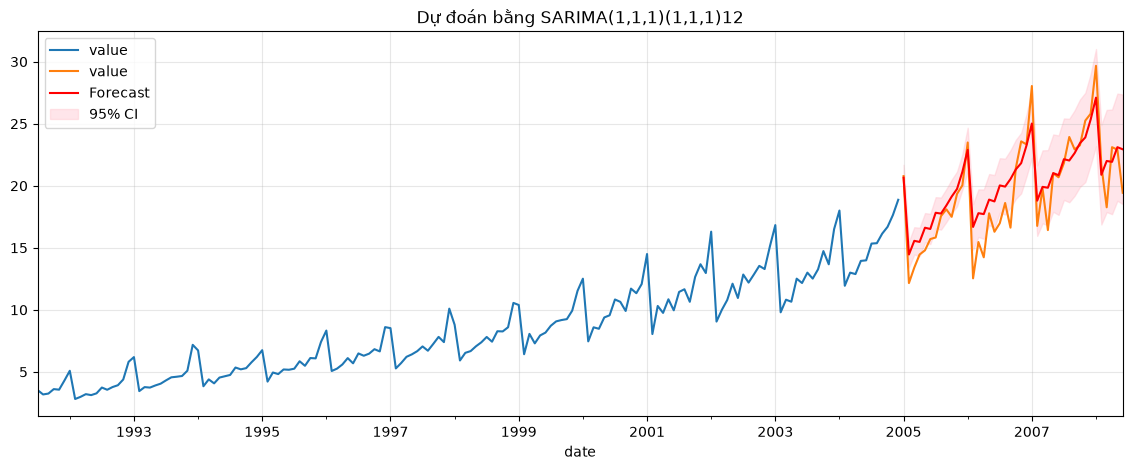

In [21]:
fc_s   = sarima_fit.get_forecast(steps=len(test_data))
pred_s = pd.Series(fc_s.predicted_mean.to_numpy(), index=test_data.index)
ci_s   = fc_s.conf_int()

fig, ax = plt.subplots(figsize=(14, 5))
train_data.plot(ax=ax, label="Train")
test_data.plot(ax=ax, label="Test")
pred_s.plot(ax=ax, label="Forecast", color="red")
ax.fill_between(ci_s.index, ci_s.iloc[:, 0], ci_s.iloc[:, 1], color="pink", alpha=0.4, label="95% CI")
ax.set_title(f"Dự đoán bằng {sarima_name}")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

In [22]:
err_s  = test_data["value"] - pred_s
mae_s  = err_s.abs().mean()
rmse_s = np.sqrt((err_s ** 2).mean())
mape_s = (err_s.abs() / test_data["value"]).mean() * 100

print(f"MAE  = {mae_s:.2f}")
print(f"RMSE = {rmse_s:.2f}")
print(f"MAPE = {mape_s:.2f}%")
print("Sai lệch lớn nhất:", err_s.abs().idxmax().date(), "=", round(err_s.abs().max(), 2))

MAE  = 1.51
RMSE = 1.95
MAPE = 8.71%
Sai lệch lớn nhất: 2006-02-01 = 4.14


**So sánh ARIMA và SARIMA trên tập test:**

| | ARIMA(1,1,1) | SARIMA(1,1,1)(1,1,1)₁₂ |
|---|---|---|
| MAE | 4.07 | **1.51** |
| RMSE | 5.18 | **1.95** |
| MAPE | 19.12% | **8.71%** |
| Sai lệch lớn nhất | 13.32 (01/2008) | **4.14 (02/2006)** |
| Ljung-Box lag 12 | ≈ 0 → còn mùa vụ | 0.12 → nhiễu trắng |

SARIMA hạ MAE ~63% và MAPE từ 19% xuống 8.7%: đúng như Phần 3 chẩn đoán, phần ARIMA bỏ sót là mùa vụ. (AIC chọn (1,1,1)(1,1,1)₁₂, BIC chọn (0,1,1)(0,1,1)₁₂ — nhóm lấy theo AIC cho nhất quán với Phần 2. Không so AIC giữa ARIMA và SARIMA vì D = 1 làm đổi chuỗi tính likelihood; hai mô hình chỉ so được qua MAE/RMSE/MAPE.)